In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import models
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

transform_scratch = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

transform_tl = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

def get_loaders(transform, batch_size=64):
    train = torchvision.datasets.CIFAR10(root='./data', train=True,
                                          download=True, transform=transform)
    test  = torchvision.datasets.CIFAR10(root='./data', train=False,
                                          download=True, transform=transform)
    return (torch.utils.data.DataLoader(train, batch_size=batch_size,
                                         shuffle=True,  num_workers=2),
            torch.utils.data.DataLoader(test,  batch_size=batch_size,
                                         shuffle=False, num_workers=2))

train_loader_s, test_loader_s = get_loaders(transform_scratch)

CLASSES = ('plane','car','bird','cat','deer',
           'dog','frog','horse','ship','truck')
print("Data loaded.")

Using device: cuda


100%|██████████| 170M/170M [53:51<00:00, 52.8kB/s]


Data loaded.


In [ ]:
class CNNScratch(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32x16x16
            # Block 2
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 64x8x8
            # Block 3
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)  # 128x4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model_scratch = CNNScratch().to(device)
print(model_scratch)
total_params = sum(p.numel() for p in model_scratch.parameters())
print(f"\nTotal parameters: {total_params:,}")

CNNScratch(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)

Total parameters: 1,147,466


In [ ]:
def train_model(model, train_loader, test_loader, epochs=15, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        # --- Train ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc  = 100. * correct / total

        # --- Validate ---
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                correct += predicted.eq(labels).sum().item()
                total += labels.size(0)

        val_loss /= total
        val_acc   = 100. * correct / total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        scheduler.step()
        print(f"Epoch [{epoch+1:02d}/{epochs}] "
              f"Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.2f}%  "
              f"Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.2f}%")

    return history

print("Training CNN from scratch...")
history_scratch = train_model(model_scratch, train_loader_s, test_loader_s, epochs=15)

Training CNN from scratch...
Epoch [01/15] Train Loss: 1.6001  Train Acc: 41.02%  Val Loss: 1.2808  Val Acc: 53.51%
Epoch [02/15] Train Loss: 1.2127  Train Acc: 56.50%  Val Loss: 1.0519  Val Acc: 62.50%
Epoch [03/15] Train Loss: 1.0430  Train Acc: 63.07%  Val Loss: 0.9250  Val Acc: 68.02%
Epoch [04/15] Train Loss: 0.9399  Train Acc: 67.23%  Val Loss: 0.8863  Val Acc: 68.29%
Epoch [05/15] Train Loss: 0.8908  Train Acc: 68.87%  Val Loss: 0.8286  Val Acc: 71.05%
Epoch [06/15] Train Loss: 0.7849  Train Acc: 72.81%  Val Loss: 0.7749  Val Acc: 73.26%
Epoch [07/15] Train Loss: 0.7541  Train Acc: 73.77%  Val Loss: 0.7369  Val Acc: 74.46%
Epoch [08/15] Train Loss: 0.7311  Train Acc: 74.82%  Val Loss: 0.7232  Val Acc: 74.66%
Epoch [09/15] Train Loss: 0.7122  Train Acc: 75.08%  Val Loss: 0.6878  Val Acc: 76.37%
Epoch [10/15] Train Loss: 0.6938  Train Acc: 75.92%  Val Loss: 0.7099  Val Acc: 75.18%
Epoch [11/15] Train Loss: 0.6514  Train Acc: 77.35%  Val Loss: 0.6765  Val Acc: 76.26%
Epoch [12/15] 

In [ ]:
train_loader_tl, test_loader_tl = get_loaders(transform_tl, batch_size=32)

model_tl = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all layers
for param in model_tl.parameters():
    param.requires_grad = False

# Replace classifier head only
model_tl.fc = nn.Sequential(
    nn.Linear(model_tl.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 10)
)

model_tl = model_tl.to(device)

trainable = sum(p.numel() for p in model_tl.parameters() if p.requires_grad)
print(f"Trainable parameters (head only): {trainable:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 86.1MB/s]


Trainable parameters (head only): 133,898


In [ ]:
print("Training transfer learning model...")
history_tl = train_model(model_tl, train_loader_tl, test_loader_tl, epochs=10, lr=1e-3)

Training transfer learning model...
Epoch [01/10] Train Loss: 0.8234  Train Acc: 71.51%  Val Loss: 0.6633  Val Acc: 76.63%
Epoch [02/10] Train Loss: 0.6980  Train Acc: 75.75%  Val Loss: 0.5811  Val Acc: 80.02%
Epoch [03/10] Train Loss: 0.6725  Train Acc: 76.75%  Val Loss: 0.5733  Val Acc: 80.09%
Epoch [04/10] Train Loss: 0.6522  Train Acc: 77.44%  Val Loss: 0.5668  Val Acc: 80.25%
Epoch [05/10] Train Loss: 0.6412  Train Acc: 77.84%  Val Loss: 0.5451  Val Acc: 81.05%
Epoch [06/10] Train Loss: 0.5867  Train Acc: 79.71%  Val Loss: 0.5447  Val Acc: 81.21%
Epoch [07/10] Train Loss: 0.5767  Train Acc: 80.07%  Val Loss: 0.5259  Val Acc: 81.94%
Epoch [08/10] Train Loss: 0.5740  Train Acc: 80.16%  Val Loss: 0.5234  Val Acc: 82.06%
Epoch [09/10] Train Loss: 0.5633  Train Acc: 80.39%  Val Loss: 0.5342  Val Acc: 81.48%
Epoch [10/10] Train Loss: 0.5593  Train Acc: 80.35%  Val Loss: 0.5295  Val Acc: 81.54%


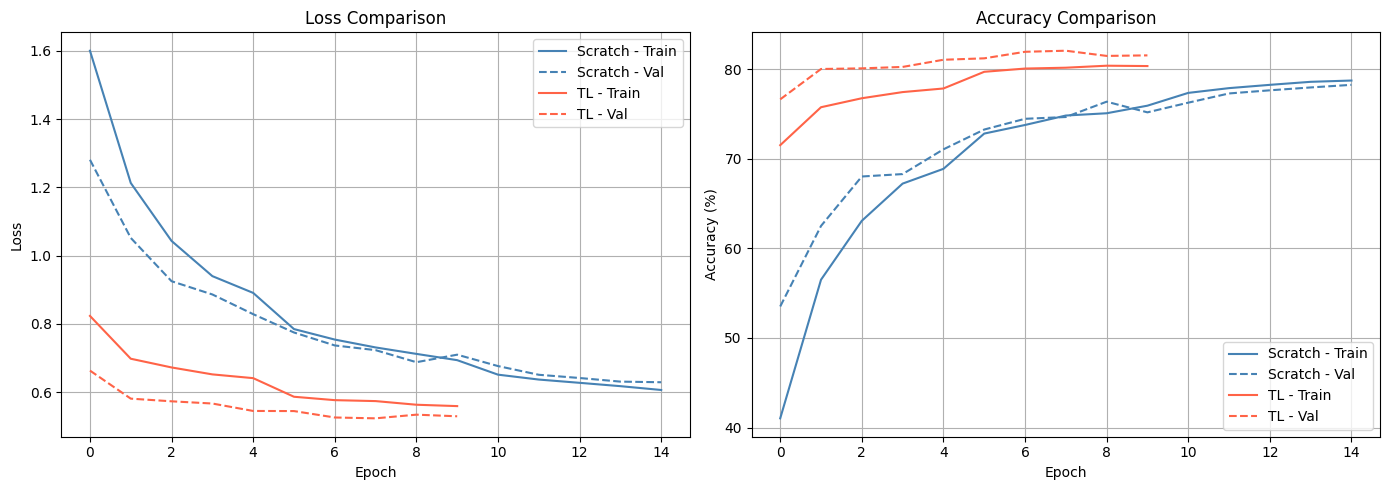

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Loss ---
axes[0].plot(history_scratch['train_loss'], label='Scratch - Train', color='steelblue')
axes[0].plot(history_scratch['val_loss'],   label='Scratch - Val',   color='steelblue', linestyle='--')
axes[0].plot(history_tl['train_loss'],      label='TL - Train',      color='tomato')
axes[0].plot(history_tl['val_loss'],        label='TL - Val',        color='tomato',    linestyle='--')
axes[0].set_title('Loss Comparison')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# --- Accuracy ---
axes[1].plot(history_scratch['train_acc'], label='Scratch - Train', color='steelblue')
axes[1].plot(history_scratch['val_acc'],   label='Scratch - Val',   color='steelblue', linestyle='--')
axes[1].plot(history_tl['train_acc'],      label='TL - Train',      color='tomato')
axes[1].plot(history_tl['val_acc'],        label='TL - Val',        color='tomato',    linestyle='--')
axes[1].set_title('Accuracy Comparison')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

In [ ]:
scratch_best = max(history_scratch['val_acc'])
tl_best      = max(history_tl['val_acc'])

print("=" * 45)
print(f"{'Model':<25} {'Best Val Acc':>15}")
print("=" * 45)
print(f"{'CNN from Scratch':<25} {scratch_best:>14.2f}%")
print(f"{'ResNet18 Transfer':<25} {tl_best:>14.2f}%")
print("=" * 45)
print(f"\nTransfer Learning gained {tl_best - scratch_best:.2f}% over scratch.")